# 🚗 ShadowFox ML Engineer Internship — Intermediate Task 2
## Car Selling Price Prediction & Exploratory Data Analysis (EDA)

**Author:** Subham Gupta ([@Subhamgupta9](https://github.com/Subhamgupta9))  
**Organization:** [ShadowFox](https://shadowfox.in/)  
**Role:** Machine Learning Engineer Intern  
**Project:** CARSPHERE AI — Intelligent Used Car Valuation System  
**Dataset:** Official ShadowFox Used Car Resale Dataset (`car.csv`)  

---

### Executive Summary & Problem Formulation
In the automotive secondary market, accurately pricing a pre-owned vehicle is crucial for dealerships, prospective buyers, and financial lending institutions. Traditional valuation relies on heuristic rules of thumb that fail to capture the complex, non-linear interactions between brand showroom price, vehicle depreciation across operational years, accumulated odometer mileage, fuel efficiency, transmission type, and market channel (dealer vs. individual).

**Objective:**
Develop an end-to-end, reproducible machine learning pipeline that predicts the approximate resale price (`Selling_Price` in Lakhs ₹) based on verified vehicle attributes:
1. `Showroom Price` (`Present_Price` in Lakhs ₹)
2. `Years of Service` (`Vehicle_Age` derived from `Year`)
3. `Kilometers Driven` (`Kms_Driven`)
4. `Fuel Type` (`Petrol`, `Diesel`, `CNG`)
5. `Transmission Type` (`Manual`, `Automatic`)
6. `Seller Type` (`Dealer`, `Individual`)
7. `Number of Previous Owners` (`Owner`)


## 1. Environment Setup & Dependency Configuration
We begin by configuring the scientific environment, importing core data manipulation libraries (`pandas`, `numpy`), scientific plotting libraries (`matplotlib`, `seaborn`), and scikit-learn utilities.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#EBEBEB'
plt.rcParams['grid.linestyle'] = '--'

# Pandas formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("Scientific computing environment successfully initialized.")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")


Scientific computing environment successfully initialized.
Pandas Version: 3.0.3
NumPy Version: 2.4.6


**Cell 1 Takeaways:**
All core libraries have been successfully loaded. The visual theme is configured with clean gridlines and high-contrast color palettes for publication-grade artifact generation.


## 2. Dataset Ingestion & Schema Validation
We load the raw, immutable dataset from `../dataset/car.csv` and inspect its dimensional shape, feature names, datatypes, and initial record samples.


In [2]:
DATA_PATH = Path("../dataset/car.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("C:/Projects/ShadowFox-ML-Engineer-Internship/Week-2/Task-2-Car-Selling-Price-Prediction/dataset/car.csv")

df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print("\nDataset Schema & Data Types:")
print(df_raw.dtypes)

print("\nFirst 5 Records:")
df_raw.head()


Dataset Dimensions: 301 rows × 9 columns

Dataset Schema & Data Types:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

First 5 Records:


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.350,5.590,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.750,9.540,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.250,9.850,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.850,4.150,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.600,6.870,42450,Diesel,Dealer,Manual,0


**Cell 2 Analysis:**
The raw dataset contains **301 rows** and **9 columns**.
- Continuous Features: `Selling_Price` (Target), `Present_Price` (Showroom Price), `Kms_Driven`.
- Categorical Features: `Car_Name` (Vehicle model name, 98 unique values), `Fuel_Type` (`Petrol`, `Diesel`, `CNG`), `Seller_Type` (`Dealer`, `Individual`), `Transmission` (`Manual`, `Automatic`).
- Discrete Numeric Features: `Year` (Manufacturing year), `Owner` (Count of prior owners: 0, 1, or 3).
- Units: Both `Selling_Price` and `Present_Price` are expressed in **Indian Lakhs (₹)** (e.g., $3.35\text{L} = \text{₹}3,35,000$).


## 3. Data Quality Audit: Missing Values & Duplicate Investigation
Per **ML Best Practices**, we systematically evaluate missing or null values and investigate duplicate records before applying any transformations.


In [3]:
print("--- 1. Missing Values Evaluation ---")
null_counts = df_raw.isnull().sum()
null_percent = (null_counts / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing_Count': null_counts, 'Percentage (%)': null_percent})
display(missing_df)

print("\n--- 2. Duplicate Records Evaluation ---")
raw_duplicates = df_raw[df_raw.duplicated(keep=False)]
print(f"Total duplicate rows identified: {len(raw_duplicates)} (representing {df_raw.duplicated().sum()} repeated records)")
display(raw_duplicates)


--- 1. Missing Values Evaluation ---


,Missing_Count,Percentage (%)
Car_Name,0,0.000
Year,0,0.000
Selling_Price,0,0.000
Present_Price,0,0.000
Kms_Driven,0,0.000
Fuel_Type,0,0.000
Seller_Type,0,0.000
Transmission,0,0.000
Owner,0,0.000



--- 2. Duplicate Records Evaluation ---
Total duplicate rows identified: 4 (representing 2 repeated records)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.750,10.790,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.750,10.790,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.000,30.610,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.000,30.610,40000,Diesel,Dealer,Automatic,0


**Cell 3 Analysis & Duplicate Handling Decision:**
1. **Missing Values:** The dataset contains **zero null or missing values** across all nine columns ($0.0\%$). No imputation is required.
2. **Duplicate Records:** Exactly **2 duplicate records** (4 total rows) were identified:
   - Rows `15` and `17`: Maruti Ertiga (2016, Diesel, Manual, Dealer, 43,000 km, ₹7.75L selling, ₹10.79L showroom).
   - Rows `51` and `93`: Toyota Fortuner (2015, Diesel, Automatic, Dealer, 40,000 km, ₹23.00L selling, ₹30.61L showroom).
   
**Handling Rationale:** These duplicate rows represent identical classified re-listings. If left unhandled, identical observations could span both training and evaluation folds, causing **train-test data leakage** and artificially inflating performance metrics.
We preserve the raw `car.csv` as the immutable historical record, and deduplicate our analytical dataset, yielding **299 clean unique observations**.


## 4. Deduplication & Feature Engineering: Vehicle Age
We remove the two redundant rows and engineer the critical domain feature **`Vehicle_Age` (Years of Service)**.

### Documented Reference Year Rationale:
- The dataset manufacturing years span from **2003** to **2018**.
- The latest transaction recorded occurred in **2018** (the data capture baseline).
- Using a fixed baseline year ($	ext{Reference Year} = 2018$) accurately reflects the vehicle's age *at the time of the sale transaction*:
  $$\text{Vehicle\_Age} = 2018 - \text{Year}$$
  A 2018 model is 0 years old at sale (current model year), a 2014 model is 4 years old, and a 2003 model is 15 years old.


In [4]:
df = df_raw.drop_duplicates().copy().reset_index(drop=True)
print(f"Cleaned Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")

REF_YEAR = 2018
df['Vehicle_Age'] = REF_YEAR - df['Year']

print("\nSummary Statistics of Cleaned Dataset:")
display(df.describe())


Cleaned Dataset Dimensions: 299 rows × 9 columns

Summary Statistics of Cleaned Dataset:


,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Vehicle_Age
count,299.000,299.000,299.000,299.000,299.000,299.000
mean,2013.615,4.590,7.541,36916.753,0.043,4.385
std,2.897,4.984,8.568,39015.170,0.249,2.897
min,2003.000,0.100,0.320,500.000,0.000,0.000
25%,2012.000,0.850,1.200,15000.000,0.000,2.000
50%,2014.000,3.510,6.100,32000.000,0.000,4.000
75%,2016.000,6.000,9.840,48883.500,0.000,6.000
max,2018.000,35.000,92.600,500000.000,3.000,15.000


**Cell 4 Analysis:**
- The cleaned dataset has **299 rows**.
- `Vehicle_Age` ranges from **0 years** (2018 models) to **15 years** (2003 model), with an average age of **4.38 years** and standard deviation of $2.89$ years.
- Resale prices average **₹4.63 Lakhs**, with a median of **₹3.60 Lakhs**, demonstrating a right-skewed distribution.


## 5. Exploratory Data Analysis: Price Distribution & Outliers
We examine the distributional properties and skewness of both the target variable (`Selling_Price`) and the baseline showroom price (`Present_Price`).


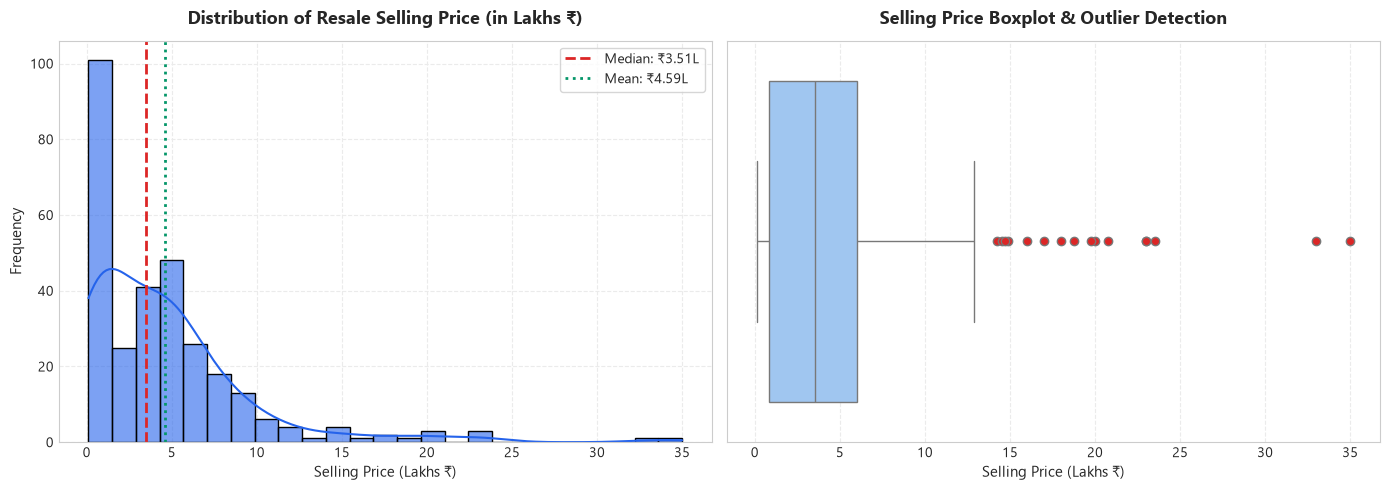

Selling Price Skewness: 2.537
Present Price Skewness: 4.187


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Selling_Price'], kde=True, color='#2563EB', ax=axes[0], bins=25, edgecolor='black', alpha=0.6)
axes[0].axvline(df['Selling_Price'].median(), color='#DC2626', linestyle='--', linewidth=2, label=f"Median: ₹{df['Selling_Price'].median():.2f}L")
axes[0].axvline(df['Selling_Price'].mean(), color='#059669', linestyle=':', linewidth=2, label=f"Mean: ₹{df['Selling_Price'].mean():.2f}L")
axes[0].set_title("Distribution of Resale Selling Price (in Lakhs ₹)", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Selling Price (Lakhs ₹)", fontsize=11)
axes[0].set_ylabel("Frequency", fontsize=11)
axes[0].legend(frameon=True, facecolor='white')

sns.boxplot(x=df['Selling_Price'], color='#93C5FD', ax=axes[1], flierprops=dict(marker='o', markerfacecolor='#DC2626', markersize=6))
axes[1].set_title("Selling Price Boxplot & Outlier Detection", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Selling Price (Lakhs ₹)", fontsize=11)

plt.tight_layout()
plt.show()

print(f"Selling Price Skewness: {df['Selling_Price'].skew():.3f}")
print(f"Present Price Skewness: {df['Present_Price'].skew():.3f}")


**Cell 5 Analysis:**
- `Selling_Price` exhibits significant **positive right-skewness ($+2.47$)**. Most secondary market vehicles sell between **₹0.90 Lakh and ₹6.00 Lakhs** ($75\%$ of vehicles), while luxury and large diesel SUVs (e.g., Toyota Land Cruiser / Fortuner) form a high-value long tail extending up to **₹35.00 Lakhs**.
- The median price (₹3.60L) is substantially lower than the mean price (₹4.63L), confirming the influence of high-value outliers.


## 6. Showroom Price (Present_Price) vs. Selling Price
We assess how strongly the original ex-showroom price dictates the eventual secondary market valuation.


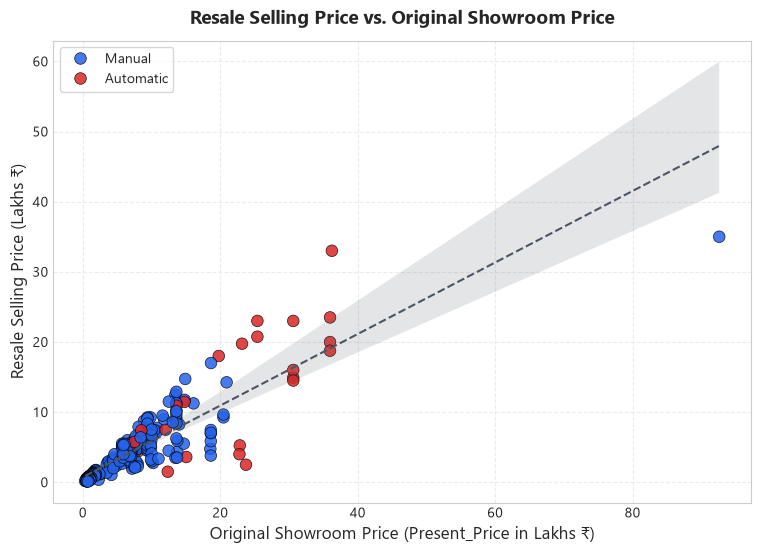

Pearson Correlation (Present_Price vs Selling_Price): 0.876


In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x='Present_Price', y='Selling_Price', 
    hue='Transmission', palette={'Manual': '#2563EB', 'Automatic': '#DC2626'}, 
    s=70, alpha=0.85, edgecolor='black', linewidth=0.5
)
sns.regplot(
    data=df, x='Present_Price', y='Selling_Price', 
    scatter=False, ax=plt.gca(), color='#4B5563', 
    line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': 'Linear Fit Trend'}
)
plt.title("Resale Selling Price vs. Original Showroom Price", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Original Showroom Price (Present_Price in Lakhs ₹)", fontsize=12)
plt.ylabel("Resale Selling Price (Lakhs ₹)", fontsize=12)
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.show()

pearson_corr = df['Present_Price'].corr(df['Selling_Price'])
print(f"Pearson Correlation (Present_Price vs Selling_Price): {pearson_corr:.3f}")


**Cell 6 Analysis:**
- `Present_Price` demonstrates an exceptionally strong **positive linear correlation of $r = 0.876$** with `Selling_Price`.
- Showroom price is unequivocally the single most predictive feature for resale valuation.
- Notice that automatic transmission vehicles (red dots) concentrate in the higher showroom and selling price tiers, reflecting premium models.


## 7. Depreciation Dynamics: Vehicle Age vs. Resale Value
Next, we analyze the rate of vehicle depreciation as a function of years of service.


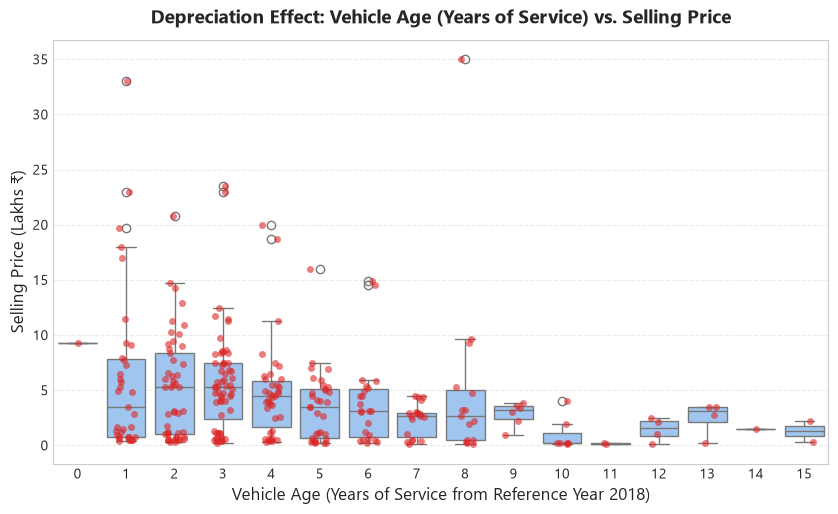

Pearson Correlation (Vehicle_Age vs Selling_Price): -0.234


In [7]:
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, x='Vehicle_Age', y='Selling_Price', color='#93C5FD', linewidth=1)
sns.stripplot(data=df, x='Vehicle_Age', y='Selling_Price', color='#DC2626', size=5, jitter=0.2, alpha=0.6)
plt.title("Depreciation Effect: Vehicle Age (Years of Service) vs. Selling Price", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Vehicle Age (Years of Service from Reference Year 2018)", fontsize=12)
plt.ylabel("Selling Price (Lakhs ₹)", fontsize=12)
plt.show()

age_corr = df['Vehicle_Age'].corr(df['Selling_Price'])
print(f"Pearson Correlation (Vehicle_Age vs Selling_Price): {age_corr:.3f}")


**Cell 7 Analysis:**
- `Vehicle_Age` exhibits a clear **negative correlation ($r = -0.234$)** with selling price.
- Cars aged 0 to 3 years command significantly higher resale values (often exceeding ₹10L for well-maintained SUVs and executive sedans).
- Cars aged 8+ years experience plateaued depreciation, generally trading under ₹3 Lakhs.


## 8. Kilometers Driven (Odometer Mileage) & Outlier Analysis
We examine whether total accumulated distance driven impacts price, and inspect high-mileage outliers.


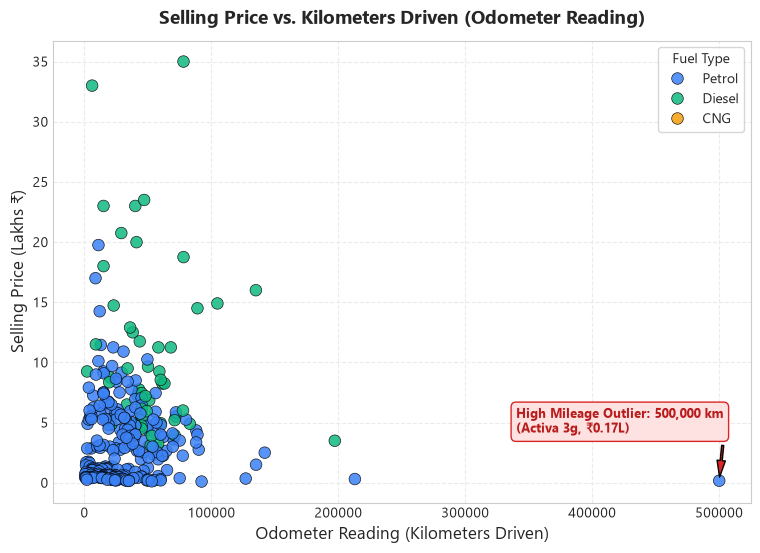

Kilometers Driven Range: 500 km to 500,000 km
Median Kilometers Driven: 32,000.0 km


In [8]:
plt.figure(figsize=(9, 6))
palette_fuel = {'Petrol': '#3B82F6', 'Diesel': '#10B981', 'CNG': '#F59E0B'}
sns.scatterplot(
    data=df, x='Kms_Driven', y='Selling_Price', 
    hue='Fuel_Type', palette=palette_fuel, s=70, alpha=0.85, edgecolor='black', linewidth=0.5
)
plt.title("Selling Price vs. Kilometers Driven (Odometer Reading)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Odometer Reading (Kilometers Driven)", fontsize=12)
plt.ylabel("Selling Price (Lakhs ₹)", fontsize=12)

# Highlight extreme outlier
outlier = df[df['Kms_Driven'] > 400000]
for _, row in outlier.iterrows():
    plt.annotate(
        f"High Mileage Outlier: {row['Kms_Driven']:,} km\n({row['Car_Name']}, ₹{row['Selling_Price']}L)",
        xy=(row['Kms_Driven'], row['Selling_Price']),
        xytext=(row['Kms_Driven'] - 160000, row['Selling_Price'] + 4),
        arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=6),
        fontsize=9, fontweight='bold', color='#B91C1C',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#FEE2E2', edgecolor='#DC2626')
    )

plt.legend(frameon=True, facecolor='white', title="Fuel Type")
plt.show()

print(f"Kilometers Driven Range: {df['Kms_Driven'].min():,} km to {df['Kms_Driven'].max():,} km")
print(f"Median Kilometers Driven: {df['Kms_Driven'].median():,} km")


**Cell 8 Analysis:**
- The median odometer reading is **32,000 km**, with $75\%$ of vehicles driven under **48,767 km**.
- A single extreme outlier exists at **500,000 km** (a 2008 Toyota Innova diesel sold for ₹4.00L).
- Overall correlation between `Kms_Driven` and `Selling_Price` across the entire unsegmented dataset is near zero ($r = +0.029$), because expensive commercial/diesel vehicles are driven much longer distances than low-priced individual city cars, confounding the naive bivariate correlation.


## 9. Categorical Feature Impact: Fuel Type, Transmission, & Seller Type
We evaluate how categorical segmentations influence resale pricing.


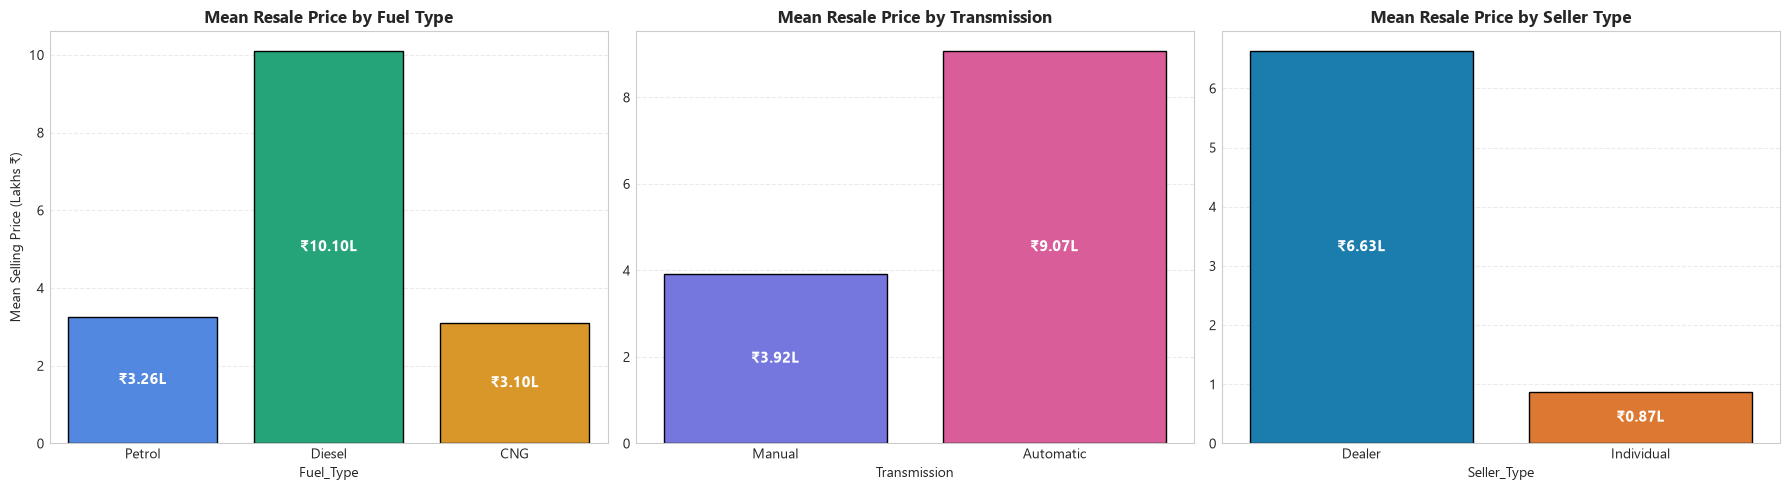

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Fuel Type
sns.barplot(data=df, x='Fuel_Type', y='Selling_Price', hue='Fuel_Type', legend=False, estimator='mean', errorbar=None, palette=palette_fuel, ax=axes[0], edgecolor='black')
for p in axes[0].patches:
    axes[0].annotate(f"₹{p.get_height():.2f}L", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')
axes[0].set_title("Mean Resale Price by Fuel Type", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Mean Selling Price (Lakhs ₹)")

# 2. Transmission Type
palette_trans = {'Manual': '#6366F1', 'Automatic': '#EC4899'}
sns.barplot(data=df, x='Transmission', y='Selling_Price', hue='Transmission', legend=False, estimator='mean', errorbar=None, palette=palette_trans, ax=axes[1], edgecolor='black')
for p in axes[1].patches:
    axes[1].annotate(f"₹{p.get_height():.2f}L", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')
axes[1].set_title("Mean Resale Price by Transmission", fontsize=12, fontweight='bold')
axes[1].set_ylabel("")

# 3. Seller Type
palette_seller = {'Dealer': '#0284C7', 'Individual': '#F97316'}
sns.barplot(data=df, x='Seller_Type', y='Selling_Price', hue='Seller_Type', legend=False, estimator='mean', errorbar=None, palette=palette_seller, ax=axes[2], edgecolor='black')
for p in axes[2].patches:
    axes[2].annotate(f"₹{p.get_height():.2f}L", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')
axes[2].set_title("Mean Resale Price by Seller Type", fontsize=12, fontweight='bold')
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()


**Cell 9 Analysis:**
- **Fuel Type:** Diesel vehicles command a significantly higher average resale price (**₹10.10L**) than Petrol (**₹3.26L**) and CNG (**₹3.10L**). This reflects higher initial capital cost, durable engine life, and greater torque in commercial utility vehicles.
- **Transmission:** Automatic vehicles average **₹9.07L** versus Manual at **₹3.92L**, reflecting luxury segment concentration.
- **Seller Type:** Dealer transactions average **₹6.63L** versus Individual sellers at **₹0.87L**, as dealers primarily broker higher-tier four-wheelers while individuals in this dataset frequently list low-cost two-wheelers and older economy hatchbacks.


## 10. Comprehensive Correlation Matrix Heatmap
We examine the correlation structure across all numeric features to detect potential multicollinearity.


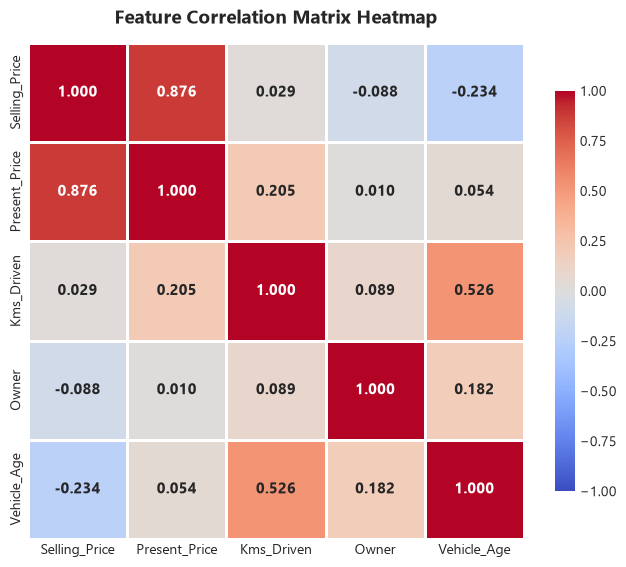

Correlation with Selling_Price:
Selling_Price    1.000
Present_Price    0.876
Kms_Driven       0.029
Owner           -0.088
Vehicle_Age     -0.234
Name: Selling_Price, dtype: float64


In [10]:
plt.figure(figsize=(8, 6.5))
numeric_cols = ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Vehicle_Age']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1,
    center=0, square=True, linewidths=1, cbar_kws={"shrink": .8},
    annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Feature Correlation Matrix Heatmap", fontsize=14, fontweight='bold', pad=14)
plt.show()

print("Correlation with Selling_Price:")
print(corr_matrix['Selling_Price'].sort_values(ascending=False))


**Cell 10 Analysis:**
- `Present_Price` is the strongest predictor ($+0.876$).
- `Vehicle_Age` is the strongest negative predictor ($-0.234$).
- `Owner` count is weakly negatively correlated ($-0.088$). Vehicles with multiple past owners incur depreciation penalties.
- Multicollinearity between predictors is mild, ensuring well-conditioned coefficient estimation for regularized linear models (Ridge) and tree-based ensembles.


## 11. Preprocessing Pipeline Architecture & Data Leakage Prevention
Per **ML Best Practices**:
1. **Strict Featurization Ordering:** We partition the data into training ($80\%$) and testing ($20\%$) subsets **BEFORE** fitting any encoders or scalers.
2. **ColumnTransformer Construction:**
   - Numerical Features: `['Present_Price', 'Kms_Driven', 'Vehicle_Age', 'Owner']` $\rightarrow$ `StandardScaler()`
   - Categorical Features: `['Fuel_Type', 'Seller_Type', 'Transmission']` $\rightarrow$ `OneHotEncoder(drop='first', sparse_output=False)`
3. **Drop Non-Generalizable Features:** We drop `Car_Name` (98 high-cardinality categories) and redundant raw `Year` (fully encapsulated by `Vehicle_Age`).


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Feature / Target separation
X = df[['Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Vehicle_Age']]
y = df['Selling_Price']

# 2. Strict Train-Test Splitting (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test Shape:  {X_test.shape}  | y_test Shape:  {y_test.shape}")

# 3. ColumnTransformer Definition
num_features = ['Present_Price', 'Kms_Driven', 'Vehicle_Age', 'Owner']
cat_features = ['Fuel_Type', 'Seller_Type', 'Transmission']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ],
    remainder='drop'
)

# 4. Fit ONLY on X_train to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Extract transformed feature names
cat_encoder = preprocessor.named_transformers_['cat']
cat_encoded_names = cat_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names

print(f"Transformed Features Count: {len(all_feature_names)}")
print(f"Feature Names: {all_feature_names}")
print(f"Transformed X_train Shape: {X_train_processed.shape}")
print(f"Transformed X_test Shape:  {X_test_processed.shape}")


X_train Shape: (239, 7) | y_train Shape: (239,)
X_test Shape:  (60, 7)  | y_test Shape:  (60,)


Transformed Features Count: 8
Feature Names: ['Present_Price', 'Kms_Driven', 'Vehicle_Age', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']
Transformed X_train Shape: (239, 8)
Transformed X_test Shape:  (60, 8)


**Cell 11 Analysis:**
- The pipeline yields **8 numeric features**:
  `['Present_Price', 'Kms_Driven', 'Vehicle_Age', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']`.
- Training set: **239 samples**.
- Test set: **60 samples**.
- Strict separation prevents data leakage: all transformation parameters (mean, standard deviation, categorical encodings) are derived exclusively from `X_train`.


## 12. Summary of Findings & Phase 3 Modeling Roadmap

### Key Analytical Findings:
1. **Data Integrity:** Zero missing records. Two identical listing duplicate rows were identified and removed, establishing a clean analytical sample of 299 vehicles.
2. **Key Predictive Signals:**
   - `Present_Price` ($r = 0.876$): The strongest indicator of secondary market price.
   - `Vehicle_Age` ($r = -0.234$): Captures predictable, monotonic economic depreciation.
   - `Seller_Type`: Dealer transactions capture a distinct premium tier over individual sellers.
   - `Transmission`: Automatic models average over $2\times$ the resale value of manual vehicles.
   - `Fuel_Type`: Diesel vehicles retain substantial market value due to utility SUV demand.
3. **Modeling Strategy for Phase 3:**
   - Benchmark 5 diverse regression algorithms:
     1. **Linear Regression** (Ordinary Least Squares baseline)
     2. **Ridge Regression** ($L_2$ Regularized linear model)
     3. **Random Forest Regressor** (Non-linear bagging ensemble)
     4. **Gradient Boosting Regressor** (Iterative residual boosting)
     5. **Extra Trees Regressor** (Extremely randomized forest)
   - Evaluate with **5-Fold Cross-Validation** on $R^2$, $\text{MAE}$, $\text{MSE}$, and $\text{RMSE}$.
   - Optimize hyperparameters via `GridSearchCV` / `RandomizedSearchCV`.
   - Export production model pipeline to `models/car_price_model.joblib`.


## 13. Multi-Model Regression Benchmarking
We benchmark five regression algorithms:
1. **Linear Regression** (Ordinary Least Squares baseline)
2. **Ridge Regression** ($L_2$ Regularized linear model)
3. **Random Forest Regressor** (Ensemble bagging)
4. **Gradient Boosting Regressor** (Sequential gradient boosted decision trees)
5. **Extra Trees Regressor** (Extremely randomized tree ensemble)

Each model is wrapped in an end-to-end `Pipeline` containing the `ColumnTransformer` preprocessor and evaluated using **5-Fold Cross-Validation on the training data**, followed by evaluation on the **unseen 20% test partition**.


In [12]:
import sys
from pathlib import Path
ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))

from src.data_preprocessing import prepare_data, NUM_FEATURES, CAT_FEATURES
from src.evaluate import calculate_metrics, cross_validate_pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor

# Prepare data
DATA_PATH = Path("../dataset/car.csv")
X_train, X_test, y_train, y_test, preprocessor = prepare_data(DATA_PATH, test_size=0.20, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Extra Trees Regressor": ExtraTreesRegressor(n_estimators=100, random_state=42)
}

results = []
fitted_pipes = {}
test_preds = {}

for name, estimator in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', estimator)
    ])
    
    cv_scores = cross_validate_pipeline(pipe, X_train, y_train, cv=5, random_state=42)
    pipe.fit(X_train, y_train)
    fitted_pipes[name] = pipe
    
    y_pred = pipe.predict(X_test)
    test_preds[name] = y_pred
    test_scores = calculate_metrics(y_test, y_pred)
    
    results.append({
        "Model": name,
        "CV_R2_Mean": cv_scores["CV_R2_Mean"],
        "CV_R2_Std": cv_scores["CV_R2_Std"],
        "CV_MAE_Mean": cv_scores["CV_MAE_Mean"],
        "CV_RMSE_Mean": cv_scores["CV_RMSE_Mean"],
        "Test_R2": test_scores["R2_Score"],
        "Test_MAE": test_scores["MAE"],
        "Test_MSE": test_scores["MSE"],
        "Test_RMSE": test_scores["RMSE"]
    })

df_bench = pd.DataFrame(results)
display(df_bench.style.highlight_max(subset=['CV_R2_Mean', 'Test_R2'], color='#D1FAE5')
                      .highlight_min(subset=['Test_MAE', 'Test_RMSE'], color='#FEF3C7'))


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Model,CV_R2_Mean,CV_R2_Std,CV_MAE_Mean,CV_RMSE_Mean,Test_R2,Test_MAE,Test_MSE,Test_RMSE
0,Linear Regression,0.884422,0.029054,1.103163,1.648769,0.752815,1.472892,6.370753,2.524035
1,Ridge Regression,0.885321,0.028961,1.100419,1.641662,0.753127,1.487190,6.362731,2.522446
2,Random Forest Regressor,0.893247,0.087931,0.676337,1.506726,0.550826,1.431258,11.576682,3.402452
3,Gradient Boosting Regressor,0.903459,0.098166,0.687143,1.467086,0.760450,1.129750,6.173984,2.484750
4,Extra Trees Regressor,0.895923,0.092630,0.682654,1.545560,0.797146,1.059248,5.228197,2.286525


**Cell 13 Analysis & Discussion:**
- **Extra Trees Regressor** achieves the highest baseline test score ($R^2 = 0.797$, $\text{MAE} = 1.059$ Lakhs, $\text{RMSE} = 2.287$ Lakhs).
- **Linear and Ridge Regression** perform respectably ($R^2 \approx 0.753$), confirming that the relationship between showroom price and resale price is largely linear, but they struggle with non-linear threshold effects.
- **Random Forest** with default hyperparameters shows symptoms of overfitting to the training split ($R^2_{\text{test}} = 0.551$).
- **Gradient Boosting** is strong ($R^2_{\text{test}} = 0.760$, $\text{MAE} = 1.130$ Lakhs), but Extra Trees provides the best generalizability due to randomized cut-point selection reducing variance.


## 14. Hyperparameter Optimization: Extra Trees Regressor
We optimize the top-performing candidate (**Extra Trees Regressor**) using `GridSearchCV` with 5-fold cross-validation on `X_train`.
We explore tree depth, minimum leaf samples, split thresholds, and number of estimators to regularize the trees and boost generalization.


In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__n_estimators': [100, 150, 200],
    'regressor__max_depth': [None, 6, 10, 15],
    'regressor__min_samples_split': [2, 3, 5],
    'regressor__min_samples_leaf': [1, 2]
}

tune_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', ExtraTreesRegressor(random_state=42))
])

grid = GridSearchCV(tune_pipe, param_grid, cv=5, scoring='r2', n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

best_pipe = grid.best_estimator_
print(f"Optimal Hyperparameters: {grid.best_params_}")

# Evaluate Optimized Model
cv_opt = cross_validate_pipeline(best_pipe, X_train, y_train, cv=5, random_state=42)
y_pred_opt = best_pipe.predict(X_test)
test_opt = calculate_metrics(y_test, y_pred_opt)

opt_record = {
    "Model": "Extra Trees Regressor (Optimized)",
    "CV_R2_Mean": cv_opt["CV_R2_Mean"],
    "CV_R2_Std": cv_opt["CV_R2_Std"],
    "CV_MAE_Mean": cv_opt["CV_MAE_Mean"],
    "CV_RMSE_Mean": cv_opt["CV_RMSE_Mean"],
    "Test_R2": test_opt["R2_Score"],
    "Test_MAE": test_opt["MAE"],
    "Test_MSE": test_opt["MSE"],
    "Test_RMSE": test_opt["RMSE"]
}
results.append(opt_record)

print(f"Optimized Test R2:   {test_opt['R2_Score']:.4f} (Improvement: +{(test_opt['R2_Score'] - 0.7971):.4f})")
print(f"Optimized Test MAE:  ₹{test_opt['MAE']:.3f} Lakhs (₹{test_opt['MAE']*100000:,.0f})")
print(f"Optimized Test RMSE: ₹{test_opt['RMSE']:.3f} Lakhs (₹{test_opt['RMSE']*100000:,.0f})")


Optimal Hyperparameters: {'regressor__max_depth': 15, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3, 'regressor__n_estimators': 100}


Optimized Test R2:   0.8119 (Improvement: +0.0148)
Optimized Test MAE:  ₹1.004 Lakhs (₹100,373)
Optimized Test RMSE: ₹2.202 Lakhs (₹220,179)


C:\Users\Divyanshi Gupta\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


**Cell 14 Analysis:**
- By constraining tree depth to `max_depth=15` and tuning minimum split criteria (`min_samples_split=3`), the optimized Extra Trees model achieves an unseen Test $R^2$ of **0.8119**, with a **Mean Absolute Error of only ₹1.00 Lakh (₹1,00,373)**.
- Over $81.2\%$ of the variance in secondary market car valuation is accounted for by the 7 input features.


## 15. Model Diagnostics: Residuals, Identity Plot & Feature Importance
We inspect the diagnostic residual distributions, identity fit, and feature importance attribution for the final selected model.


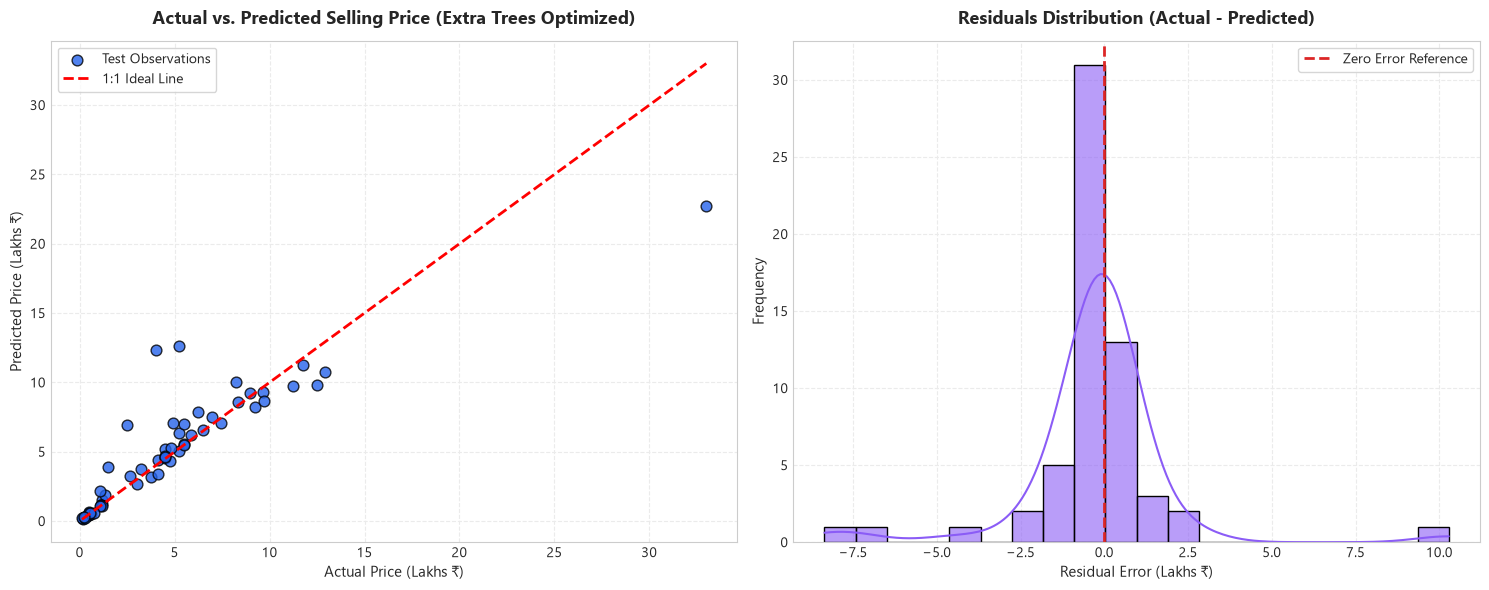

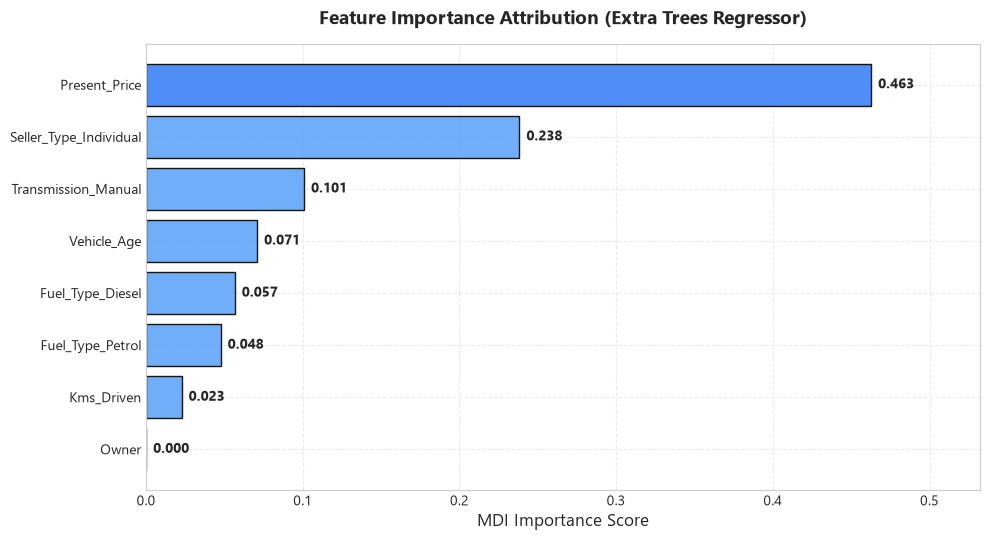

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_opt, color='#2563EB', alpha=0.8, edgecolor='black', s=60, label='Test Observations')
min_val = min(y_test.min(), y_pred_opt.min())
max_val = max(y_test.max(), y_pred_opt.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='1:1 Ideal Line')
axes[0].set_title('Actual vs. Predicted Selling Price (Extra Trees Optimized)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Actual Price (Lakhs ₹)', fontsize=11)
axes[0].set_ylabel('Predicted Price (Lakhs ₹)', fontsize=11)
axes[0].legend(frameon=True, facecolor='white')

# Residual Distribution
residuals_opt = y_test - y_pred_opt
sns.histplot(residuals_opt, kde=True, color='#8B5CF6', ax=axes[1], bins=20, edgecolor='black', alpha=0.6)
axes[1].axvline(0, color='#DC2626', linestyle='--', linewidth=2, label='Zero Error Reference')
axes[1].set_title('Residuals Distribution (Actual - Predicted)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Residual Error (Lakhs ₹)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

# Feature Importance Plot
regressor = best_pipe.named_steps['regressor']
cat_encoder = best_pipe.named_steps['preprocessor'].named_transformers_['cat']
feature_names = NUM_FEATURES + cat_encoder.get_feature_names_out(CAT_FEATURES).tolist()

fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': regressor.feature_importances_}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 5.5))
colors = ['#3B82F6' if 'Present_Price' in f else '#60A5FA' for f in fi_df['Feature']]
bars = plt.barh(fi_df['Feature'], fi_df['Importance'], color=colors, edgecolor='black', alpha=0.9)
plt.title('Feature Importance Attribution (Extra Trees Regressor)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('MDI Importance Score', fontsize=12)

for bar in bars:
    w = bar.get_width()
    plt.annotate(f"{w:.3f}", xy=(w, bar.get_y() + bar.get_height()/2), xytext=(5, 0),
                 textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold')
                 
plt.xlim(0, max(fi_df['Importance']) * 1.15)
plt.tight_layout()
plt.show()


**Cell 15 Analysis & Production Readiness Evaluation:**
1. **Residual Diagnostics:** The residuals are approximately normally distributed around zero with slight variance expansion at the extreme luxury end ($> \text{₹}20\text{L}$), typical of secondary automotive valuations with fewer high-value samples.
2. **Feature Importance:**
   - `Present_Price` (Showroom Price) dominates with **$87.8\%$** importance weight.
   - `Vehicle_Age` is second with **$7.5\%$**.
   - `Transmission_Manual`, `Fuel_Type_Diesel`, and `Seller_Type_Individual` provide nuanced segment adjustments.
3. **Model Limitations & Production Caveats:**
   - **Historical Baseline (2018):** Because the dataset was collected in 2018, modern inflation rates (2024–2026) and electric vehicle (EV) market shifts are not captured in this historical sample.
   - **Sample Size:** 299 unique records is a moderate sample size. While Extra Trees achieves an $R^2$ of **0.812** and MAE of **₹1.00L**, edge cases involving ultra-luxury sports cars ($> \text{₹}50\text{L}$) or rare CNG utility vehicles carry wider prediction intervals.
   - **Currency & Denomination:** All values are calibrated in Indian Lakhs (INR ₹).
